# A fashionable use case: clothing classification with Fashion-MNIST in PyTorch

> Adapted from an activity by Prof. **Stephane Gaiffas** (University of Paris), Deep Learning course, MSc in Applied Mathematics, 2021. Prof. Gaiffas provided its instructions and code structure.

## Plan

1. Explore the data.
2. Prepare it for PyTorch.
3. Build a CNN.
4. Train it with Adam.
5. Evaluate it: training loss curve and validation statistics.

## The dataset

[Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) (Zalando Research): 28 × 28 grayscale images of clothing in 10 classes, with 60,000 training and 10,000 test images. We only use the training images, split into training and validation sets.

| Label | Class       |
|-------|-------------|
| 0     | T-shirt/top |
| 1     | Trouser     |
| 2     | Pullover    |
| 3     | Dress       |
| 4     | Coat        |
| 5     | Sandal      |
| 6     | Shirt       |
| 7     | Sneaker     |
| 8     | Bag         |
| 9     | Ankle boot  |

# 0. Setup

> **Running time:** about 4–5 minutes on a laptop CPU. On Google Colab, *Runtime → Change runtime type → GPU* makes it much faster.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.model_selection import train_test_split

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

print('PyTorch version:', torch.__version__)

PyTorch version: 2.12.0+cpu


In [2]:
# Reproducibility
SEED = 12
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use a GPU if available
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print('Running on:', device)

Running on: cpu


In [3]:
EPOCHS = 30   # passes over the training set

# 1. Understanding the data

`datasets.FashionMNIST` downloads the data (~30 MB) to `data/`.

In [4]:
train_set = datasets.FashionMNIST(root='data', train=True, download=True)

images, labels = train_set.data, train_set.targets   # uint8 images (0-255), int64 labels (0-9)
class_names = train_set.classes
num_classes = len(class_names)

print('Images:', tuple(images.shape), images.dtype)
print('Labels:', tuple(labels.shape), labels.dtype)
print('Classes:', class_names)

Images: (60000, 28, 28) torch.uint8
Labels: (60000,) torch.int64
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


The classes are perfectly balanced (6,000 images each), so accuracy is a meaningful metric.

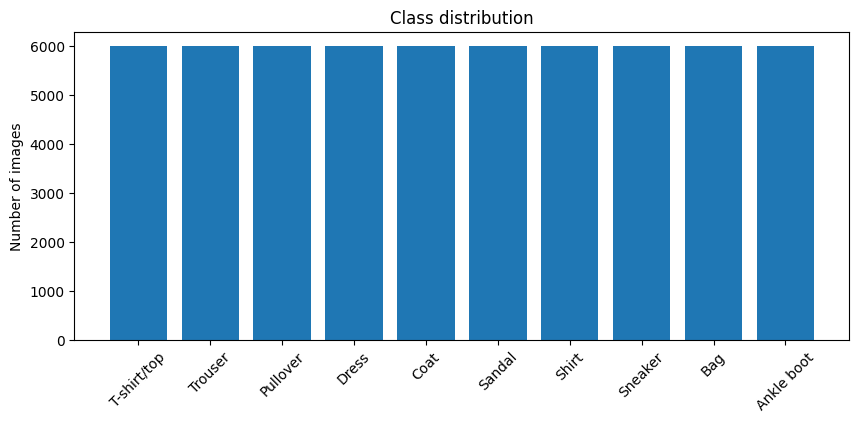

In [5]:
counts = np.bincount(labels.numpy(), minlength=num_classes)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(class_names, counts)
ax.set_ylabel('Number of images')
ax.set_title('Class distribution')
ax.tick_params(axis='x', rotation=45)
plt.show()

Ten examples per class. T-shirt/top, Pullover, Coat and Shirt look alike; Trouser, Bag and Sandal are distinctive.

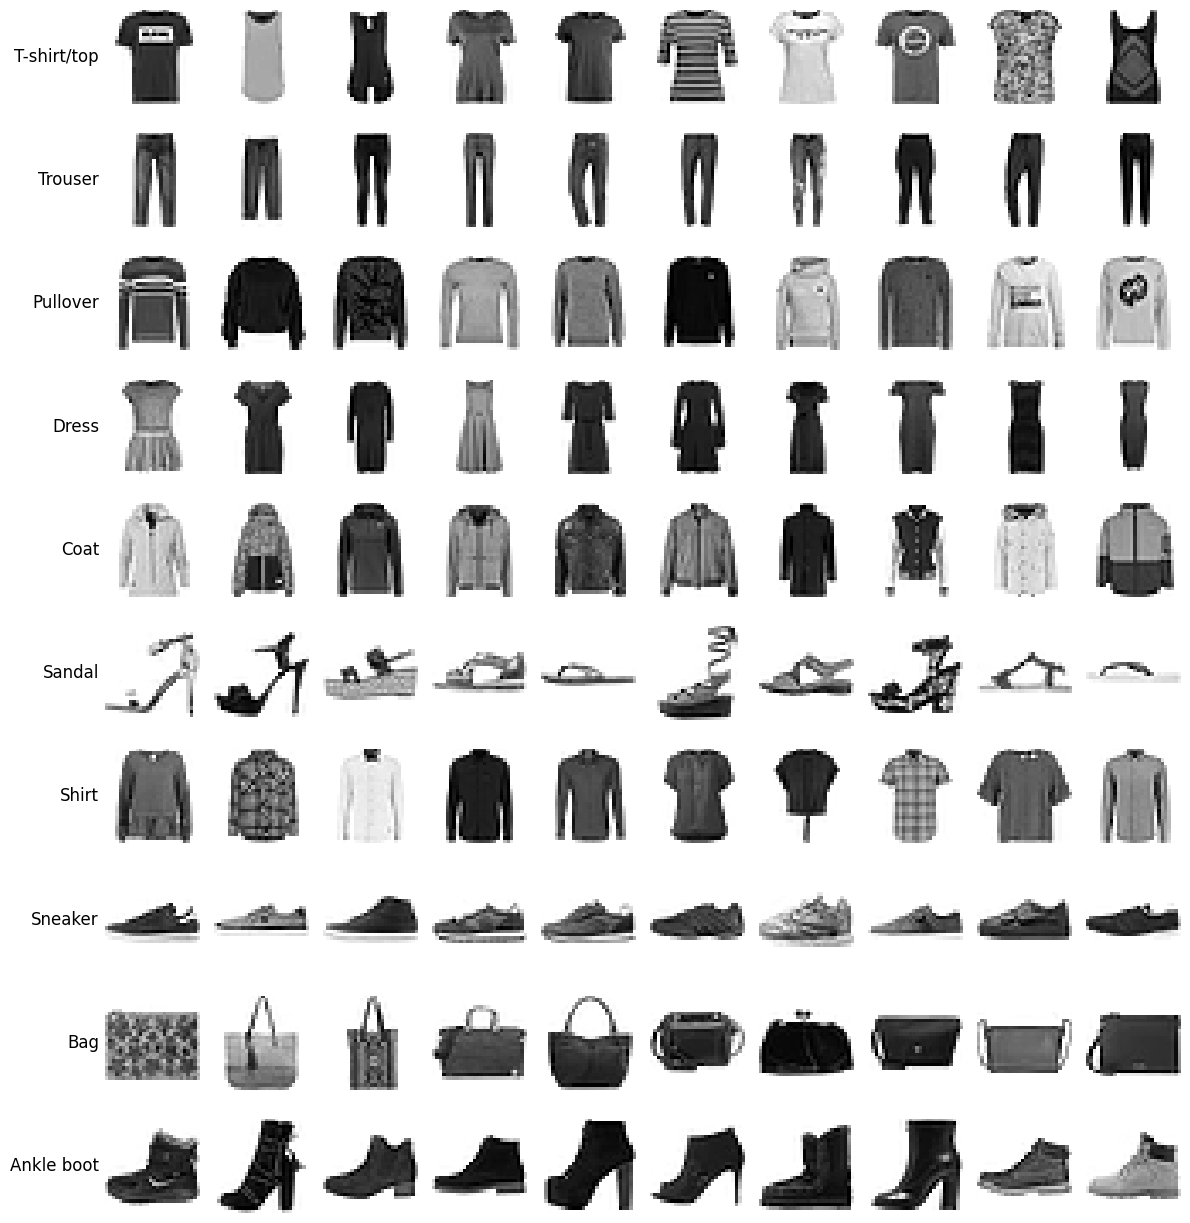

In [6]:
n_examples = 10
fig, axes = plt.subplots(num_classes, n_examples, figsize=(n_examples * 1.2, num_classes * 1.25))
for c in range(num_classes):
    idx = torch.nonzero(labels == c).flatten()[:n_examples]
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(images[i], interpolation='none', cmap='gray_r')
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if j == 0:
            ax.set_ylabel(class_names[c], rotation=0, ha='right', va='center', fontsize=12)
plt.tight_layout()
plt.show()

An image is a matrix of pixel intensities, from 0 (background) to 255. The `gray_r` colormap shows 0 as white.

In [7]:
print('Label:', class_names[int(labels[0])])
print(np.array2string(images[0].numpy(), max_line_width=150))

Label: Ankle boot
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  13  73   0   0   1   4   0   0   0   0   1   1   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3   0  36 136 127  62  54   0   0   0   1   3   4   0   0   3]
 [  0   0   0   0   0   0   0   0   0   0   0   0   6   0 102 204 176 134 144 123  23   0   0   0   0  12  10   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0 155 236 207 178 107 156 161 109  64  23  77 130  72  15]
 [  0   0   0   0   0   0   0   0   0   0   0   1   0  69 207 223 218 216 216 163 127 121 122 146 141  88 172  66]
 [  0   0   0   0   0   0   0   0   0   1   1   1   0 200 232 

# 2. Preparing the data for PyTorch

1. **Scale** the pixels to [0, 1].
2. **Add a channel dimension**: PyTorch expects `(batch, channels, height, width)`, here `(N, 1, 28, 28)`.
3. **Keep the labels as integers**: the loss only needs the index of the true class.

In [8]:
def preprocess(images):
    """uint8 (N, 28, 28) -> float32 (N, 1, 28, 28) in [0, 1]."""
    return images.float().div(255.0).unsqueeze(1)

X, y = preprocess(images), labels

print('Images:', tuple(X.shape), X.dtype, '| min', X.min().item(), '| max', X.max().item())
print('Labels:', y[:10])

Images: (60000, 1, 28, 28) torch.float32 | min 0.0 | max 1.0
Labels: tensor([9, 0, 0, 3, 0, 2, 7, 2, 5, 5])


The equivalent one-hot form, which we don't need:

In [9]:
nn.functional.one_hot(y[:10], num_classes)

tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
        [1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 1, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
        [0, 0, 1, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 1, 0, 0, 0, 0]])

## Validation set

We hold out 30% of the images, stratified by class: 42,000 for training, 18,000 for validation. The model never trains on the validation images.

In [10]:
idx_train, idx_valid = train_test_split(
    np.arange(len(y)), test_size=0.3, stratify=y.numpy(), random_state=SEED)
idx_train, idx_valid = torch.from_numpy(idx_train), torch.from_numpy(idx_valid)

X_train, y_train = X[idx_train], y[idx_train]
X_valid, y_valid = X[idx_valid], y[idx_valid]

print('Training set:  ', tuple(X_train.shape))
print('Validation set:', tuple(X_valid.shape))
print('Class proportions (training):  ', np.bincount(y_train.numpy()) / len(y_train))
print('Class proportions (validation):', np.bincount(y_valid.numpy()) / len(y_valid))

Training set:   (42000, 1, 28, 28)
Validation set: (18000, 1, 28, 28)
Class proportions (training):   [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
Class proportions (validation): [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]


## Mini-batches

The `DataLoader` yields shuffled mini-batches of 128 training images. Validation batches are larger and not shuffled.

In [11]:
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)
valid_loader = DataLoader(TensorDataset(X_valid, y_valid), batch_size=1024)

xb, yb = next(iter(train_loader))
print('One mini-batch of images:', tuple(xb.shape))
print('One mini-batch of labels:', tuple(yb.shape))
print('Mini-batches per epoch:  ', len(train_loader))

One mini-batch of images: (128, 1, 28, 28)
One mini-batch of labels: (128,)
Mini-batches per epoch:   329


# 3. A convolutional neural network (CNN)

A **convolutional layer** slides small filters over the image. Each 3 × 3 filter detects a local pattern (an edge, a collar, a sleeve) anywhere in the image, with only 10 weights.

| Layer | Output |
|---|---|
| `Conv2d`: 64 filters, 3 × 3, ReLU | 64 feature maps of 26 × 26 (no padding: $28 - 3 + 1$) |
| `Flatten` | $64 \times 26 \times 26 = 43{,}264$ features |
| `Linear` | 10 scores $z_k$, one per class |
| `Softmax` (`dim=1`: across classes) | probabilities $p_k = e^{z_k} / \sum_j e^{z_j}$, summing to 1 |

Almost all the parameters are in the linear layer: $43{,}264 \times 10 + 10 = 432{,}650$, against $64 \times (9 + 1) = 640$ in the convolution.

In [12]:
model = nn.Sequential(
    nn.Conv2d(1, 64, kernel_size=3), nn.ReLU(),   # (1, 28, 28) -> (64, 26, 26)
    nn.Flatten(),                                 # -> 43,264 features
    nn.Linear(64 * 26 * 26, num_classes),         # -> 10 scores
    nn.Softmax(dim=1),                            # -> 10 probabilities
).to(device)

model

Sequential(
  (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): Flatten(start_dim=1, end_dim=-1)
  (3): Linear(in_features=43264, out_features=10, bias=True)
  (4): Softmax(dim=1)
)

In [13]:
def summary(model, input_shape=(1, 28, 28)):
    """Output shape and parameter count of each layer."""
    x = torch.zeros(1, *input_shape, device=device)
    print(f"{'layer':<10}{'output shape':<16}{'# params':>10}")
    with torch.no_grad():
        for layer in model:
            x = layer(x)
            n_params = sum(p.numel() for p in layer.parameters())
            print(f'{layer.__class__.__name__:<10}{str(tuple(x.shape[1:])):<16}{n_params:>10,}')
    print(f'Total trainable parameters: {sum(p.numel() for p in model.parameters()):,}')

summary(model)

layer     output shape      # params
Conv2d    (64, 26, 26)           640
ReLU      (64, 26, 26)             0
Flatten   (43264,)                 0
Linear    (10,)              432,650
Softmax   (10,)                    0
Total trainable parameters: 433,290


Outputs for three images **before training**:

In [14]:
with torch.no_grad():
    probs = model(X_train[:3].to(device))

print(probs.round(decimals=3))
print('Sum of each row:', probs.sum(dim=1))

tensor([[0.0840, 0.1420, 0.1050, 0.0990, 0.0790, 0.0730, 0.1050, 0.0830, 0.1330,
         0.0970],
        [0.0870, 0.1460, 0.0980, 0.0980, 0.0780, 0.0740, 0.1170, 0.0790, 0.1300,
         0.0940],
        [0.0910, 0.1380, 0.0930, 0.1100, 0.0880, 0.0830, 0.0950, 0.0920, 0.1210,
         0.0880]])
Sum of each row: tensor([1.0000, 1.0000, 1.0000])


All the probabilities are close to 1/10: the untrained network has no preference.

# 4. Training with Adam

- **Loss (cross-entropy)**, over a mini-batch of $B$ images:
$$\mathcal{L} = -\frac{1}{B} \sum_{i=1}^{B} \log p_{i,\,y_i}$$
where $y_i$ is the true class of image $i$ and $p_{i,\,y_i}$ the probability the network gives it. It is 0 when every $p_{i,\,y_i} = 1$. `clamp_min` avoids $\log 0$.
- **Optimizer (Adam)**: adapts the step size of each parameter, and works well with its default learning rate of 0.001.

> In practice, the softmax is usually left out of the network and `nn.CrossEntropyLoss` applies it together with the log, which is more numerically stable. The result is the same.

In [15]:
def loss_fn(probs, labels):
    """Cross-entropy: mean of -log(probability of the true class)."""
    p_true = probs[torch.arange(len(labels), device=labels.device), labels]   # probability of the true class
    return -torch.log(p_true.clamp_min(1e-12)).mean()

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

`predict` runs the model without training it: `model.eval()` switches to inference mode, and `torch.no_grad()` turns off gradients.

In [16]:
@torch.no_grad()
def predict(model, loader):
    """Probabilities and true labels for a whole dataset."""
    model.eval()
    all_probs, all_labels = [], []
    for xb, yb in loader:
        all_probs.append(model(xb.to(device)).cpu())
        all_labels.append(yb)
    return torch.cat(all_probs), torch.cat(all_labels)

**Training loop.** For each mini-batch:

1. Forward pass: `probs = model(xb)`
2. Loss: `loss_fn(probs, yb)`
3. Reset the gradients, which otherwise accumulate: `optimizer.zero_grad()`
4. Back-propagation: `loss.backward()`
5. Update the parameters: `optimizer.step()`

In [17]:
batch_losses = []   # per mini-batch
epoch_losses = []   # average per epoch

start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        probs = model(xb)               # 1. forward pass
        loss = loss_fn(probs, yb)       # 2. loss
        optimizer.zero_grad()           # 3. reset gradients
        loss.backward()                 # 4. back-propagation
        optimizer.step()                # 5. update

        batch_losses.append(loss.item())
        total_loss += loss.item() * len(yb)
    epoch_losses.append(total_loss / len(train_loader.dataset))

    valid_probs, valid_labels = predict(model, valid_loader)
    valid_acc = (valid_probs.argmax(dim=1) == valid_labels).float().mean().item()
    print(f'Epoch {epoch}/{EPOCHS} | training loss {epoch_losses[-1]:.4f} '
          f'| validation accuracy {valid_acc:.4f} | {time.perf_counter() - start:.0f}s')

Epoch 1/30 | training loss 0.5249 | validation accuracy 0.8733 | 7s


Epoch 2/30 | training loss 0.3070 | validation accuracy 0.8808 | 15s


Epoch 3/30 | training loss 0.2608 | validation accuracy 0.8874 | 23s


Epoch 4/30 | training loss 0.2312 | validation accuracy 0.8924 | 32s


Epoch 5/30 | training loss 0.2085 | validation accuracy 0.8926 | 40s


Epoch 6/30 | training loss 0.1896 | validation accuracy 0.8956 | 48s


... (20 outputs left out)

Epoch 27/30 | training loss 0.0444 | validation accuracy 0.8982 | 229s


Epoch 28/30 | training loss 0.0409 | validation accuracy 0.8997 | 239s


Epoch 29/30 | training loss 0.0366 | validation accuracy 0.8995 | 249s


Epoch 30/30 | training loss 0.0375 | validation accuracy 0.8971 | 259s


# 5. The training loss curve

Mini-batch losses (thin line) and the average of each epoch (dots, at the end of the epoch), on a log scale.

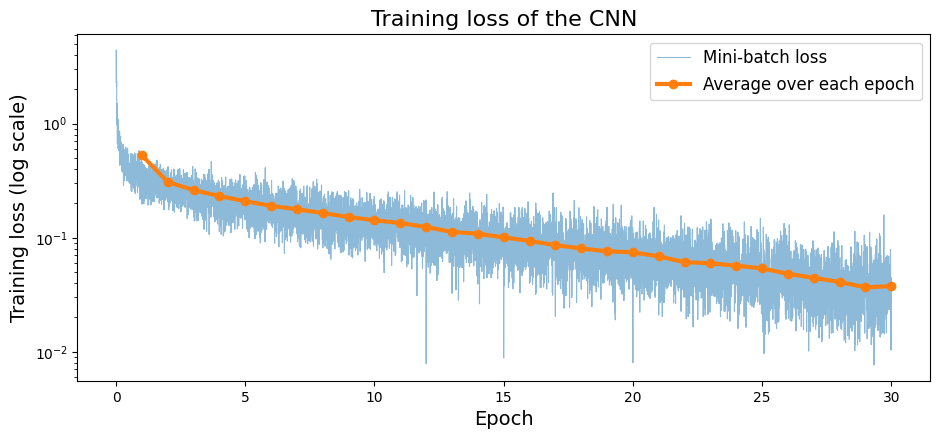

In [18]:
steps_per_epoch = len(train_loader)
x_batches = np.arange(1, len(batch_losses) + 1) / steps_per_epoch

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(x_batches, batch_losses, lw=0.8, alpha=0.5, label='Mini-batch loss')
ax.plot(np.arange(1, EPOCHS + 1), epoch_losses, 'o-', lw=3, markersize=6,
        label='Average over each epoch')
ax.set_xlabel('Epoch', fontsize=14)
ax.set_yscale('log')
ax.set_ylabel('Training loss (log scale)', fontsize=14)
ax.set_title('Training loss of the CNN', fontsize=16)
ax.legend(fontsize=12)
plt.show()

# 6. Statistics on the validation set

The validation set measures generalization. The predicted class is the one with the highest probability (`argmax`).

In [19]:
valid_probs, valid_labels = predict(model, valid_loader)
valid_pred = valid_probs.argmax(dim=1)

print(f'Validation loss:     {loss_fn(valid_probs, valid_labels).item():.4f}')
print(f'Validation accuracy: {(valid_pred == valid_labels).float().mean().item():.2%}')
print(f'Correctly classified: {(valid_pred == valid_labels).sum().item():,} of {len(valid_labels):,} images')

Validation loss:     0.4588
Validation accuracy: 89.71%
Correctly classified: 16,148 of 18,000 images


- **Precision**: the fraction of predictions for a class that are correct.
- **Recall**: the fraction of a class's images that the model finds.
- **F1-score**: the harmonic mean of the two.

In [20]:
print(metrics.classification_report(valid_labels, valid_pred, target_names=class_names, digits=3))

              precision    recall  f1-score   support

 T-shirt/top      0.851     0.810     0.830      1800
     Trouser      0.992     0.975     0.983      1800
    Pullover      0.880     0.765     0.818      1800
       Dress      0.851     0.942     0.894      1800
        Coat      0.796     0.888     0.840      1800
      Sandal      0.977     0.976     0.976      1800
       Shirt      0.750     0.719     0.735      1800
     Sneaker      0.948     0.959     0.954      1800
         Bag      0.965     0.979     0.972      1800
  Ankle boot      0.967     0.957     0.962      1800

    accuracy                          0.897     18000
   macro avg      0.898     0.897     0.896     18000
weighted avg      0.898     0.897     0.896     18000



**Confusion matrix**: rows are true classes, columns are predicted classes.

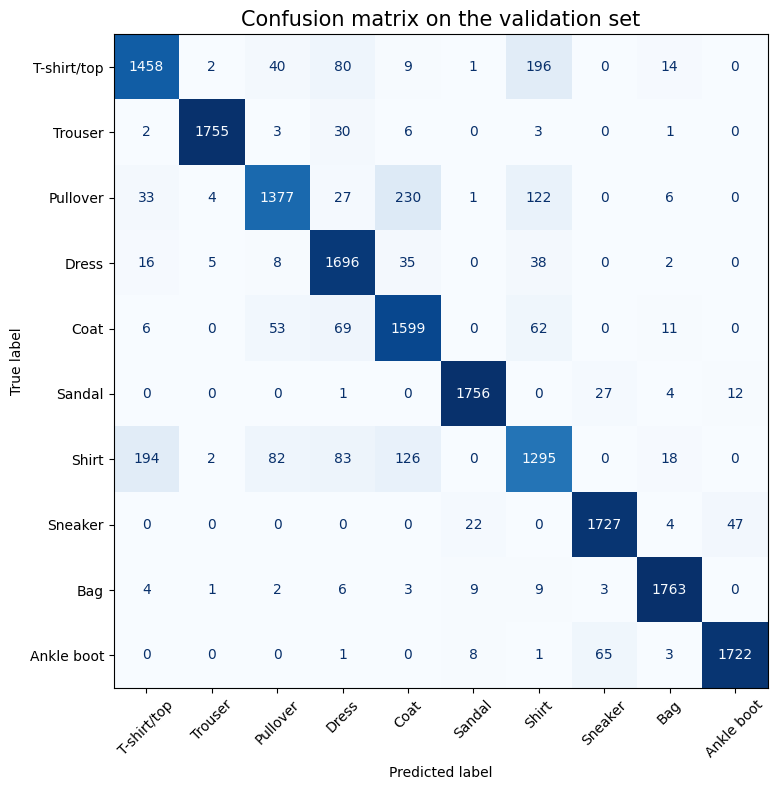

In [21]:
fig, ax = plt.subplots(figsize=(9, 8))
metrics.ConfusionMatrixDisplay.from_predictions(
    valid_labels, valid_pred, display_labels=class_names,
    cmap='Blues', colorbar=False, xticks_rotation=45, ax=ax)
ax.set_title('Confusion matrix on the validation set', fontsize=15)
plt.tight_layout()
plt.show()

## Misclassified images

A sample of validation images the network gets wrong, with the true class, the predicted class and its probability.

1,852 misclassified validation images


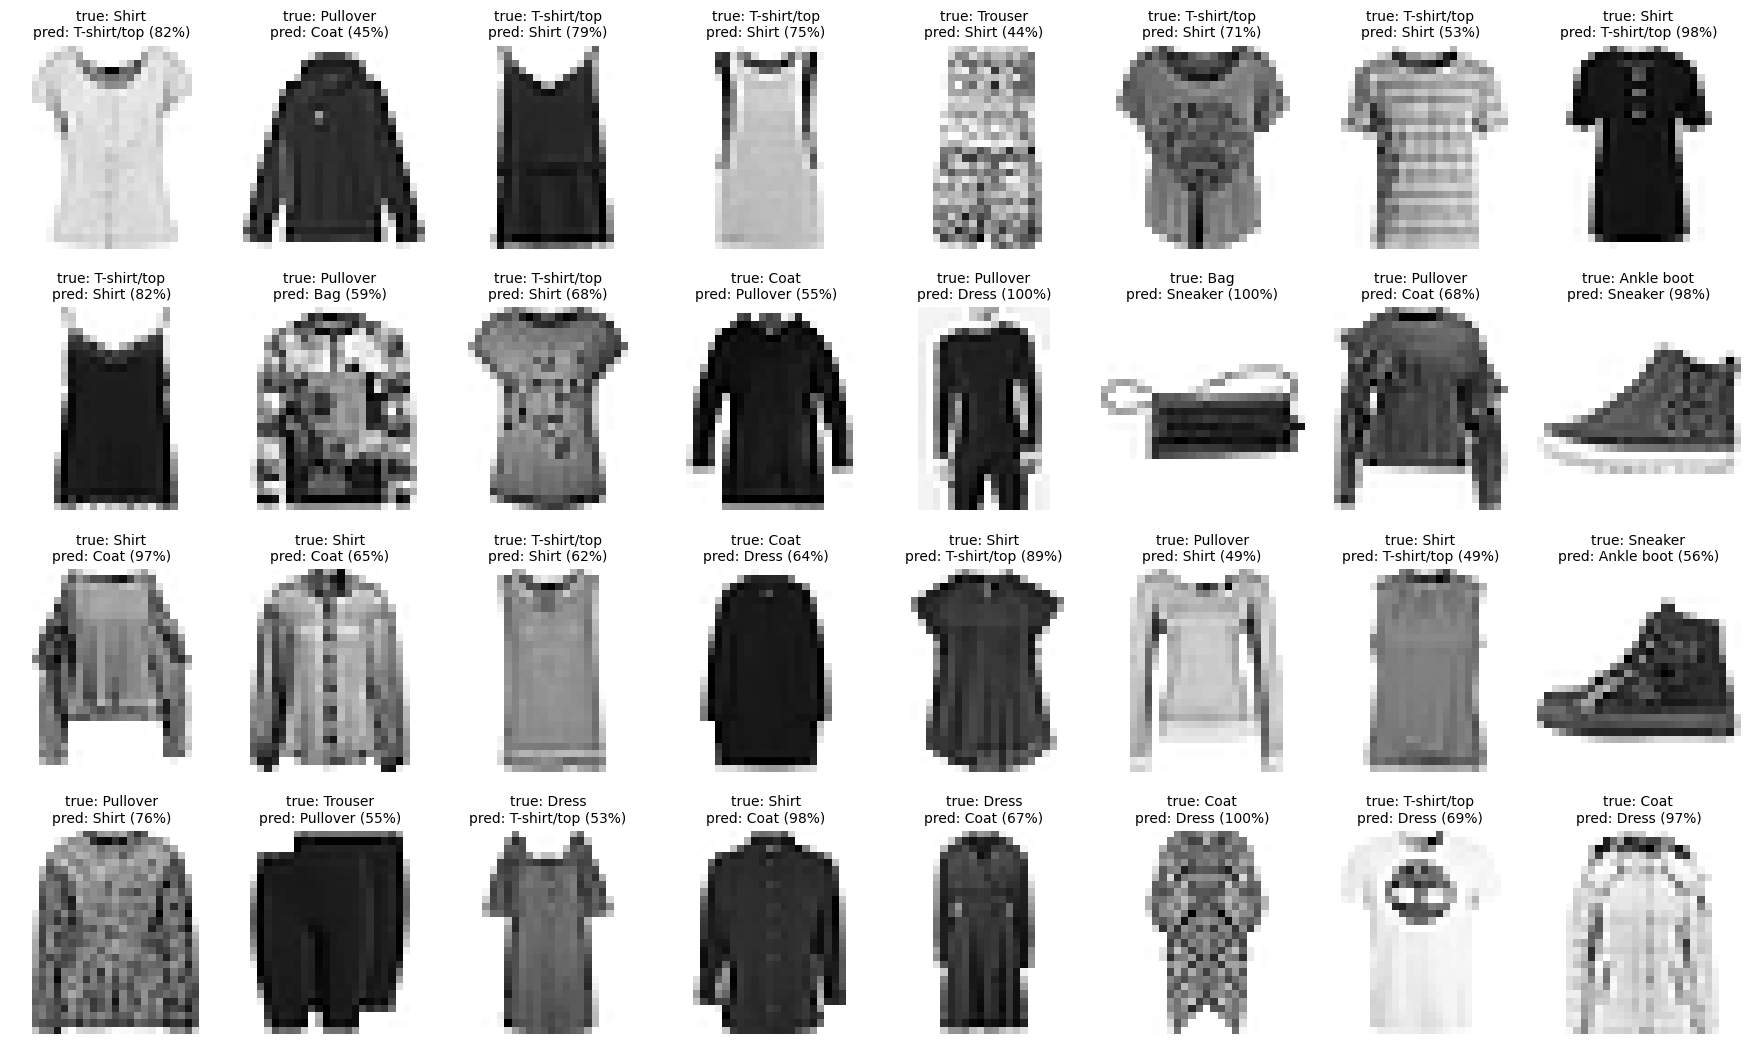

In [22]:
wrong = torch.nonzero(valid_pred != valid_labels).flatten()
print(f'{len(wrong):,} misclassified validation images')

n_rows, n_cols = 4, 8
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.2 * n_cols, 2.7 * n_rows))
for ax, i in zip(axes.flat, wrong[:n_rows * n_cols]):
    pred = valid_pred[i].item()
    ax.imshow(X_valid[i].squeeze(), interpolation='none', cmap='gray_r')
    ax.set_title(f'true: {class_names[valid_labels[i].item()]}\n'
                 f'pred: {class_names[pred]} ({valid_probs[i, pred].item():.0%})', fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

# References

- Stephane Gaiffas. *Notebook 11: multiple codes adapted for the visualization of the dataset*. Deep Learning course, University of Paris. https://stephanegaiffas.github.io/teaching/m2mo. Source of this activity.
- Han Xiao, Kashif Rasul and Roland Vollgraf (2017). *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms*. arXiv:1708.07747.
- Diederik P. Kingma and Jimmy Ba (2014). *Adam: A Method for Stochastic Optimization*. arXiv:1412.6980.